In [ ]:
import tensorflow as tf
from tensorflow import keras
# import Numpy
import numpy as np
# Import Matplolib
import matplotlib.pyplot as plt
print("Loading MNIST dataset...")
(train_images, train_labels), (test_images, test_labels) = keras.datasets.mnist.load_data()
print("Dataset loaded! ✅")
print(train_images.shape)
print(train_labels.shape)
print(test_labels.shape)
print(test_labels.shape)




Loading MNIST dataset...
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Dataset loaded! ✅
(60000, 28, 28)
(60000,)
(10000,)
(10000,)


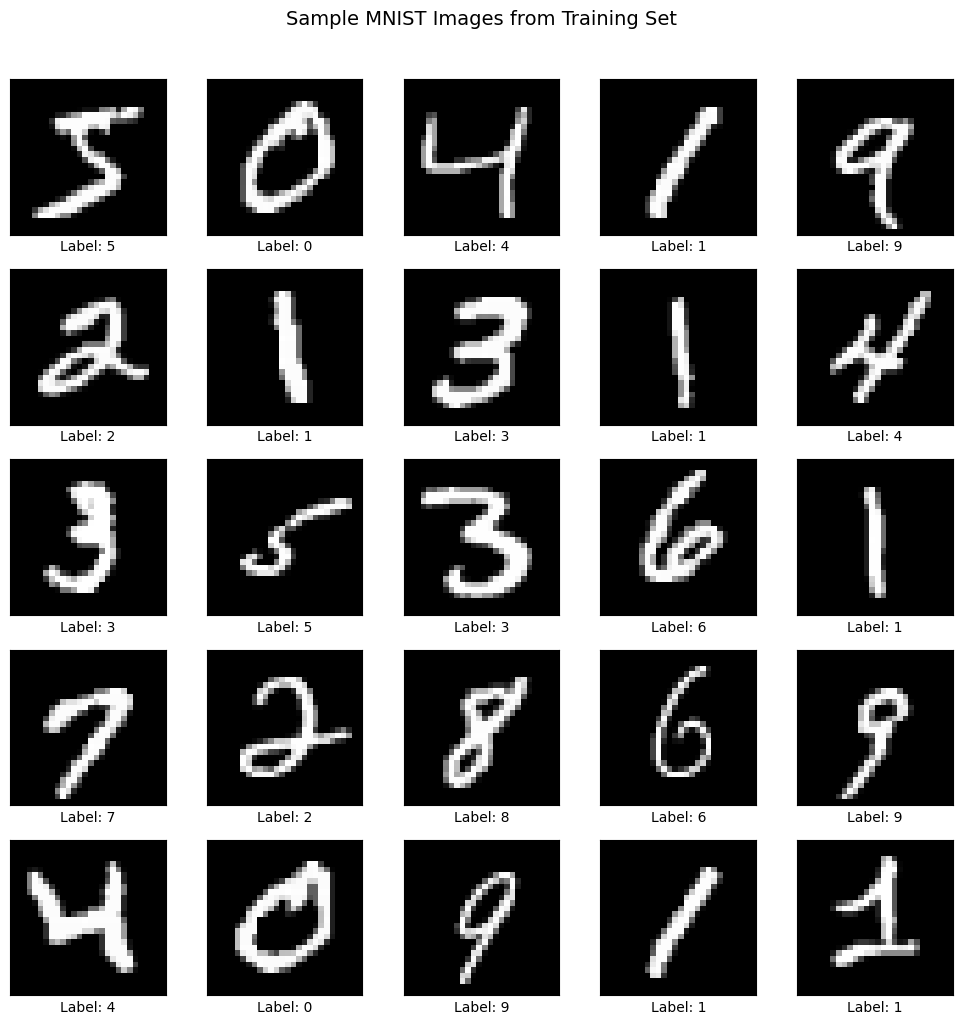

These are handwritten digits our model will learn to recognize!


In [ ]:
# ============================================================
# STEP 2C: VISUALIZE SOME IMAGES
# ============================================================
# Let's actually SEE what the data looks like!
# We will display the first 25 training images with their labels.

plt.figure(figsize=(10, 10))  # Create a 10x10 inch figure

for i in range(25):  # Show 25 images
    plt.subplot(5, 5, i + 1)     # Create a grid of 5 rows x 5 columns
    plt.xticks([])               # Remove x-axis tick marks
    plt.yticks([])               # Remove y-axis tick marks
    plt.grid(False)              # No grid lines
    plt.imshow(train_images[i], cmap='gray')   # Show image in grayscale
    plt.xlabel(f"Label: {train_labels[i]}", fontsize=10)  # Show the true label

plt.suptitle("Sample MNIST Images from Training Set", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()
print("These are handwritten digits our model will learn to recognize!")

In [ ]:
train_images_flat = train_images.reshape(-1, 28 * 28)
test_images_flat  = test_images.reshape(-1, 28 * 28)

print("Before flattening:", train_images.shape)
print("After  flattening:", train_images_flat.shape)


train_images_norm = train_images_flat.astype('float32') / 255.0
test_images_norm  = test_images_flat.astype('float32') / 255.0

print("\nBefore normalization — pixel range:", train_images_flat.min(), "to", train_images_flat.max())
print("After  normalization — pixel range:", train_images_norm.min(), "to", train_images_norm.max())
print("\nPreprocessing complete! ✅")




Before flattening: (60000, 28, 28)
After  flattening: (60000, 784)

Before normalization — pixel range: 0 to 255
After  normalization — pixel range: 0.0 to 1.0

Preprocessing complete! ✅


In [ ]:
model = keras.Sequential([

    # --- INPUT LAYER ---
    # This tells Keras the shape of each input sample.
    # Each image is now a flat array of 784 values.
    keras.layers.Input(shape=(784,)),

    # --- HIDDEN LAYER 1 ---
    # Dense = fully connected layer
    # 512 = number of neurons in this layer
    # activation='relu' = ReLU activation function
    #   ReLU: if input < 0, output 0; else output the input
    #   Why ReLU? It helps the model learn complex patterns
    keras.layers.Dense(512, activation='relu'),

    # --- DROPOUT (Regularization) ---
    # Dropout randomly sets 20% of neurons to 0 during training
    # This forces other neurons to learn the same features
    # Result: the model becomes more ROBUST and less likely to OVERFIT
    # (Overfitting = memorizing training data but failing on new data)
    keras.layers.Dropout(0.2),

    # --- HIDDEN LAYER 2 ---
    # Another Dense layer with 256 neurons
    # The network gets narrower as we go deeper — this forces it to
    # extract the most important features
    keras.layers.Dense(256, activation='relu'),

    # --- DROPOUT ---
    keras.layers.Dropout(0.2),

    # --- OUTPUT LAYER ---
    # 10 neurons = one for each digit class (0, 1, 2, ..., 9)
    # activation='softmax' = converts raw scores to PROBABILITIES
    # Example output: [0.01, 0.02, 0.95, 0.01, ...] → digit 2 is most likely!
    # All 10 probabilities add up to 1.0
    keras.layers.Dense(10, activation='softmax')

], name="MNIST_Classifier")

# Print a summary of the model — very useful to understand the architecture!
print("Model Architecture:")
model.summary()

Model Architecture:


Model: "MNIST_Classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 535,818 (2.04 MB)

 Trainable params: 535,818 (2.04 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# ============================================================
# STEP 4B: COMPILE THE MODEL
# ============================================================
# After building, we must COMPILE the model — this sets up:
#   1. Optimizer   — HOW the model updates its weights
#   2. Loss        — HOW we measure how wrong the model is
#   3. Metrics     — WHAT we track during training

model.compile(

    # OPTIMIZER: Adam is an advanced gradient descent algorithm
    # It automatically adjusts learning rate — very popular and effective
    # Learning rate (lr) controls how big a step we take during updates
    optimizer=keras.optimizers.Adam(learning_rate=0.001),

    # LOSS FUNCTION: sparse_categorical_crossentropy
    # Used for multi-class classification problems
    # 'sparse' = labels are integers (0, 1, 2, ... 9), not one-hot encoded
    # This measures how far our predictions are from true labels
    # Lower loss = better predictions
    loss='sparse_categorical_crossentropy',

    # METRICS: we track 'accuracy' — the percentage of correct predictions
    metrics=['accuracy']
)

print("Model compiled successfully! ✅")
print("\nOptimizer: Adam")
print("Loss:      Sparse Categorical Crossentropy")
print("Metric:    Accuracy")

Model compiled successfully! ✅

Optimizer: Adam
Loss:      Sparse Categorical Crossentropy
Metric:    Accuracy


In [12]:
# ============================================================
# STEP 5: TRAIN THE MODEL
# ============================================================

print("Starting training... this may take a few minutes ⏳")
print("Watch how the accuracy increases each epoch!\n")

# model.fit() = the training function
history = model.fit(

    train_images_norm,    # Training images (preprocessed)
    train_labels,         # True labels for training images

    epochs=10,            # Train for 10 epochs (10 full passes over data)
                          # More epochs = more learning (but too many = overfitting!)

    batch_size=128,       # Process 128 images at a time before updating weights
                          # Smaller batch = slower but more accurate updates
                          # Larger batch = faster but may miss some patterns

    validation_split=0.1, # Keep 10% of training data for validation
                          # This helps us see if model is overfitting

    verbose=1             # Show training progress (1=progress bar, 2=one line per epoch)
)

print("\nTraining complete! ✅")

Starting training... this may take a few minutes ⏳
Watch how the accuracy increases each epoch!

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9925 - loss: 0.0228 - val_accuracy: 0.9835 - val_loss: 0.0656
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9930 - loss: 0.0206 - val_accuracy: 0.9827 - val_loss: 0.0748
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9930 - loss: 0.0204 - val_accuracy: 0.9803 - val_loss: 0.0762
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9935 - loss: 0.0195 - val_accuracy: 0.9827 - val_loss: 0.0728
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9936 - loss: 0.0195 - val_accuracy: 0.9823 - val_loss: 0.0770
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9941 - loss: 0.0175 - val_accuracy: 0.9818 - val_loss: 0.0873
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9940 - loss: 0.0171 - val_accuracy: 0.9847 - val_loss: 0.0773
Epoch 8

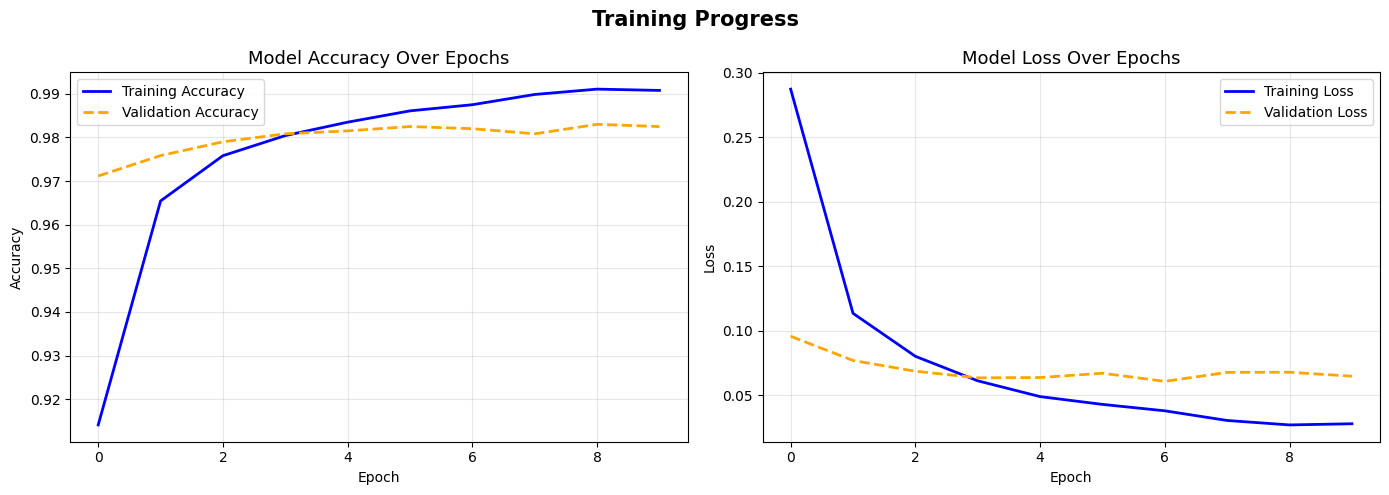

In [ ]:
# ============================================================
# STEP 5B: PLOT TRAINING HISTORY
# ============================================================
# The 'history' object stores accuracy and loss for each epoch.
# Plotting this helps us understand how well training went.

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- Plot 1: Accuracy ---
axes[0].plot(history.history['accuracy'],     label='Training Accuracy',   color='blue',  linewidth=2)
axes[0].plot(history.history['val_accuracy'], label='Validation Accuracy', color='orange', linewidth=2, linestyle='--')
axes[0].set_title('Model Accuracy Over Epochs', fontsize=13)
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(True, alpha=0.3)
# Good sign: both curves increase and stay close together
# Bad sign (overfitting): train goes up, validation goes down

# --- Plot 2: Loss ---
axes[1].plot(history.history['loss'],     label='Training Loss',   color='blue',  linewidth=2)
axes[1].plot(history.history['val_loss'], label='Validation Loss', color='orange', linewidth=2, linestyle='--')
axes[1].set_title('Model Loss Over Epochs', fontsize=13)
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True, alpha=0.3)
# Good sign: loss decreases and both curves stay close together

plt.suptitle('Training Progress', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

In [13]:
# ============================================================
# STEP 6: EVALUATE ON TEST DATA
# ============================================================

# model.evaluate() computes loss and accuracy on the test set
test_loss, test_accuracy = model.evaluate(
    test_images_norm,  # Test images (preprocessed the same way as training)
    test_labels,       # True labels
    verbose=0          # Don't show progress bar
)

print("=" * 40)
print("  FINAL TEST RESULTS")
print("=" * 40)
print(f"  Test Loss:     {test_loss:.4f}")
print(f"  Test Accuracy: {test_accuracy * 100:.2f}%")
print("=" * 40)
print(f"\n  The model correctly identified {test_accuracy * 100:.1f}%")
print(f"  of the 10,000 test images it had NEVER seen before!")
print(f"  That means {int(test_accuracy * 10000)} out of 10,000 correct predictions! 🎉")

  FINAL TEST RESULTS
  Test Loss:     0.0901
  Test Accuracy: 98.14%

  The model correctly identified 98.1%
  of the 10,000 test images it had NEVER seen before!
  That means 9814 out of 10,000 correct predictions! 🎉


In [ ]:
# ============================================================
# STEP 7A: GET MODEL PREDICTIONS
# ============================================================

# model.predict() returns an array of probabilities for EACH image
# Shape: (10000, 10) — 10000 images, each with 10 probability scores
predictions = model.predict(test_images_norm, verbose=0)

print("Predictions shape:", predictions.shape)
print("\nExample — predictions for the first test image:")
print(np.round(predictions[0], 3))  # Round to 3 decimal places
print(f"\nSum of all probabilities: {predictions[0].sum():.4f}")
# Should be exactly 1.0 because Softmax outputs sum to 1

# np.argmax() finds the index with the highest probability
predicted_label = np.argmax(predictions[0])
true_label = test_labels[0]
confidence = predictions[0][predicted_label] * 100

print(f"\nPredicted digit: {predicted_label} (confidence: {confidence:.1f}%)")
print(f"True digit:      {true_label}")
print(f"Correct?         {'✅ Yes' if predicted_label == true_label else '❌ No'}")

Predictions shape: (10000, 10)

Example — predictions for the first test image:
[0. 0. 0. 0. 0. 0. 0. 1. 0. 0.]

Sum of all probabilities: 1.0000

Predicted digit: 7 (confidence: 100.0%)
True digit:      7
Correct?         ✅ Yes


ValueError: num must be an integer with 1 <= num <= 15, not 16

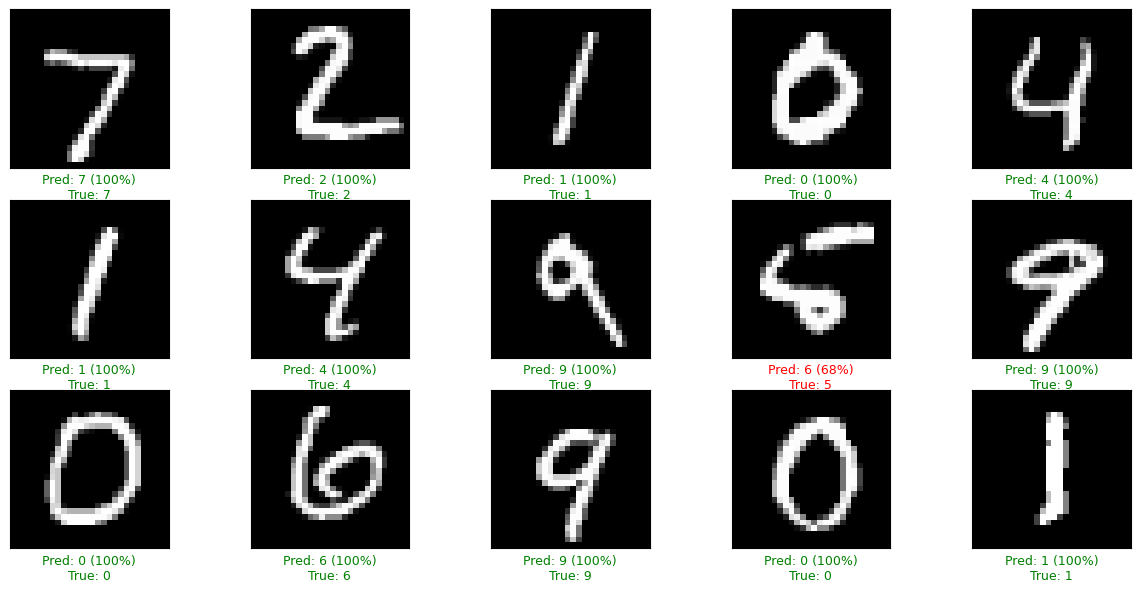

In [ ]:
plt.figure(figsize=(15, 7))

for i in range(25):
  plt.subplot(3, 5, i + 1)
  plt.xticks([])
  plt.yticks([])
  plt.grid(False)

  # Show the image (use the original unflattened test_images for display)
  plt.imshow(test_images[i], cmap='gray')

  # Get prediction and confidence
  pred = np.argmax(predictions[i])
  true = test_labels[i]
  conf = predictions[i][pred] * 100

  # Color: green if correct, red if wrong
  color = 'green' if pred == true else 'red'
  plt.xlabel(
        f"Pred: {pred} ({conf:.0f}%)\nTrue: {true}",
        color=color,
        fontsize=9
    )

plt.suptitle("Model Predictions on Test Images\n(Green = Correct, Red = Wrong)",
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()